# 04 - Protótipo: suspensão de contas em cascatas de desinformação

**SMAC03 Grafos (UNIFEI, 2026), Cenário 2: Propagação de Desinformação em Redes Sociais**

Este notebook mostra, em poucos passos, o que o protótipo faz:

1. representa uma cascata de compartilhamentos como uma **árvore direcionada com raiz**;
2. calcula as **métricas estruturais e temporais**;
3. **simula a suspensão** de k contas (centrais ou aleatórias) e mede o **alcance restante**.

**Sobre os dados.** As seções 1 a 5 usam cascatas **sintéticas**, geradas só para demonstrar o método. A seção 6 aplica o mesmo código a cascatas reais do UPFD Politifact. Os resultados completos (UPFD Politifact e Twitter15/16) são produzidos por `python executar_analise.py`.

As métricas e a simulação vêm do próprio protótipo (pasta `src/`), então os números seguem as mesmas definições do relatório.

In [1]:
import sys
from pathlib import Path

# permite importar o src/ quando o notebook roda dentro da pasta notebooks
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from src.metricas import calcular_metricas
from src.robustez import alcance_restante, curva_remocao, usuarios_centrais, vertices_por_usuario

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COR_CENTRAIS, COR_ALEATORIAS = "#d1495b", "#2e86ab"

## 1. Gerando cascatas de exemplo

Cada nova conta compartilha a partir da **raiz**, com probabilidade `p_raiz`, ou a partir de uma conta que já compartilhou, com preferência por quem já repassou para mais pessoas. Cada compartilhamento recebe um horário.

- `p_raiz` alto gera uma cascata em **estrela**, como no Twitter15/16, onde cerca de 83% dos repasses vêm direto da fonte;
- `p_raiz` menor gera uma cascata **ramificada**, como no Politifact, onde cerca de 61% vêm direto da fonte.

In [2]:
def gerar_cascata(n=150, p_raiz=0.8, semente=0, escala_h=2.0):
    """Gera uma cascata sintética no mesmo formato das cascatas reais."""
    rng = np.random.default_rng(semente)
    inicio = pd.Timestamp("2020-01-01")
    G = nx.DiGraph(raiz=0, rotulo="sintetica")

    # a raiz é a notícia, sem usuário e sem horário, como nos dados reais
    G.add_node(0, usuario=None, horario=pd.NaT)
    repasses = [0]
    horas = 0.0
    for i in range(1, n):
        # o intervalo entre compartilhamentos segue uma distribuição exponencial
        horas += rng.exponential(escala_h)
        if i == 1 or rng.random() < p_raiz:
            pai = 0
        else:
            # escolhe o pai com mais chance para quem já repassou mais (sem a raiz)
            pesos = np.array(repasses[1:i]) + 1.0
            pai = 1 + rng.choice(i - 1, p=pesos / pesos.sum())
        G.add_node(i, usuario=f"conta{i}", horario=inicio + pd.Timedelta(hours=horas))
        G.add_edge(pai, i)
        repasses[pai] += 1
        repasses.append(0)
    return G


estrela = gerar_cascata(150, p_raiz=0.83, semente=1)
ramificada = gerar_cascata(150, p_raiz=0.6, semente=1)
print(estrela)
print(ramificada)

DiGraph with 150 nodes and 149 edges
DiGraph with 150 nodes and 149 edges


## 2. Visualizando a árvore

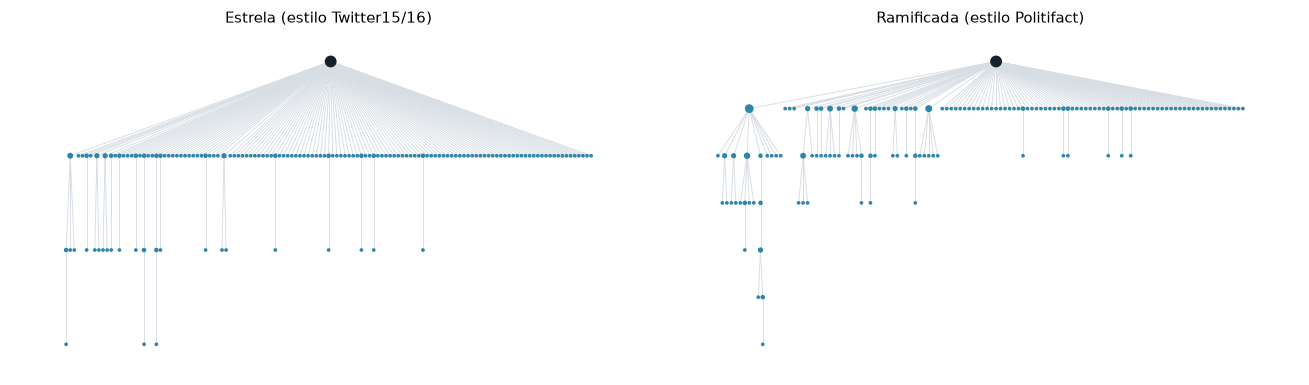

In [3]:
def posicoes(G):
    """Calcula as posições em níveis, com a raiz no topo."""
    raiz = G.graph["raiz"]
    nivel = nx.single_source_shortest_path_length(G, raiz)
    x, proxima_folha = {}, [0]

    # cada folha recebe a próxima posição x e cada pai fica no meio dos filhos
    def visitar(v):
        filhos = list(G.successors(v))
        if not filhos:
            x[v] = proxima_folha[0]
            proxima_folha[0] += 1
            return
        for f in filhos:
            visitar(f)
        x[v] = (x[filhos[0]] + x[filhos[-1]]) / 2

    visitar(raiz)
    return {v: (x[v], -nivel[v]) for v in G}


def desenhar(G, removidos=(), ax=None, titulo=""):
    """Desenha a cascata destacando as contas suspensas e quem perdeu o caminho até a raiz."""
    ax = ax or plt.gca()
    raiz = G.graph["raiz"]
    removidos = set(removidos)

    # vértices que continuam ligados à raiz depois das suspensões
    vivos = nx.descendants(G.subgraph([v for v in G if v not in removidos]), raiz) | {raiz}

    # preto: raiz, vermelho: suspensa, azul: ainda alcançada, cinza: perdeu o caminho
    cores = ["#14212b" if v == raiz else "#d1495b" if v in removidos
             else "#2e86ab" if v in vivos else "#c5ccd2" for v in G]
    tamanhos = [60 if v == raiz else 40 if v in removidos
                else 6 + 3 * min(G.out_degree(v), 12) for v in G]
    pos = posicoes(G)
    nx.draw_networkx_edges(G, pos, ax=ax, arrows=False, edge_color="#d6dde3", width=0.6)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=cores, node_size=tamanhos, linewidths=0)
    ax.set_title(titulo, fontsize=10)
    ax.axis("off")


fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
desenhar(estrela, ax=ax[0], titulo="Estrela (estilo Twitter15/16)")
desenhar(ramificada, ax=ax[1], titulo="Ramificada (estilo Politifact)")
plt.tight_layout()
plt.show()

## 3. Métricas da cascata

As mesmas medidas do relatório: tamanho, profundidade, largura máxima, viralidade estrutural (distância média entre todos os pares de vértices), fração de repasses direto da raiz, maior amplificador (maior grau de saída entre os usuários, sem contar a raiz) e velocidade.

In [4]:
# calcular_metricas recebe um dicionário de cascatas e devolve uma linha por cascata
tabela = calcular_metricas({"estrela": estrela, "ramificada": ramificada})
tabela.drop(columns=["noticia", "rotulo"]).set_index("arvore").T.round(2)

arvore,estrela,ramificada
tamanho,150.00,150.00
profundidade,3.00,6.00
largura_maxima,124.00,91.00
viralidade_estrutural,2.35,3.07
fracao_direto_da_raiz,0.83,0.61
grau_max_usuario,3.00,9.00
tempo_ate_metade_h,145.18,141.11
fracao_primeiras_24h,0.10,0.08


## 4. Simulando a suspensão de contas

- **Contas centrais**: as k contas de maior grau de saída (a raiz não é suspensa).
- **Contas aleatórias**: k contas sorteadas ao acaso (média de 20 sorteios), usadas como baseline.
- **Alcance restante**: fração dos compartilhamentos que continuam ligados à raiz. Suspender uma conta corta toda a subárvore que dependia dela (simulação estática).

In [ ]:
def contas_centrais(G, k):
    """Devolve os vértices das k contas de maior grau de saída."""
    grupos = vertices_por_usuario(G)
    return [v for u in usuarios_centrais(G, grupos)[:k] for v in grupos[u]]


# demonstração visual: 5 contas centrais suspensas na cascata ramificada
k = 5
removidos = contas_centrais(ramificada, k)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
desenhar(ramificada, ax=ax[0], titulo="Original")
desenhar(ramificada, removidos=removidos, ax=ax[1],
         titulo=f"{k} contas centrais suspensas: alcance restante = {alcance_restante(ramificada, removidos):.2f}")
plt.tight_layout()
plt.show()

## 5. Centrais e aleatórias em várias cascatas

Repetimos o experimento em 40 cascatas sintéticas de cada tipo e tiramos a média, como na curva de robustez do relatório.

In [ ]:
def media_curvas(p_raiz, n_cascatas=40):
    """Curva média de alcance restante em várias cascatas sintéticas."""
    curvas = [curva_remocao(gerar_cascata(150, p_raiz, semente=s), k_max=10, semente=s)
              for s in range(n_cascatas)]
    return pd.concat(curvas).groupby(["estrategia", "k"])["alcance"].mean().unstack("estrategia")


fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, (nome, p) in zip(ax, [("Estrela (p_raiz = 0,83)", 0.83), ("Ramificada (p_raiz = 0,6)", 0.6)]):
    media = media_curvas(p)
    a.plot(media.index, media["centrais"], "-o", color=COR_CENTRAIS, ms=3, label="contas centrais")
    a.plot(media.index, media["aleatoria"], "--o", color=COR_ALEATORIAS, ms=3, label="contas aleatórias")
    a.set_title(nome, fontsize=10)
    a.set_xlabel("Contas suspensas (k)")

    # quantas vezes mais alcance se perde suspendendo centrais em vez de aleatórias, com k = 10
    razao = (1 - media["centrais"].iloc[-1]) / (1 - media["aleatoria"].iloc[-1])
    print(f"{nome}: com k = 10, suspender centrais tira {razao:.1f} vezes mais alcance que aleatórias")
ax[0].set_ylabel("Alcance restante (fração)")
ax[0].legend(frameon=False)
plt.tight_layout()
plt.show()

**Leitura.** Nos dois tipos de cascata, suspender as contas de maior grau de saída derruba o alcance muito mais do que suspender contas ao acaso. A estrutura indica **onde** agir, mas não **o que** suspender: uma conta central de uma cascata verdadeira também derruba o alcance dela.

## 6. Aplicando a cascatas reais

O mesmo código roda sobre as cascatas reais do UPFD Politifact, que já estão no repositório. Abaixo, uma cascata falsa e uma verdadeira de tamanho parecido, antes e depois de suspender as 5 contas mais centrais. Nos dados reais a mesma conta pode aparecer mais de uma vez na cascata, por isso podem surgir mais de 5 vértices vermelhos.

In [ ]:
from src.cascata import carregar_cascatas

reais = carregar_cascatas()
tabela_reais = calcular_metricas(reais)

# escolhe uma cascata falsa e uma verdadeira com cerca de 100 vértices
exemplos = {}
for rotulo in ("fake", "real"):
    sub = tabela_reais[tabela_reais["rotulo"] == rotulo]
    exemplos[rotulo] = reais[sub.loc[(sub["tamanho"] - 100).abs().idxmin(), "arvore"]]

fig, ax = plt.subplots(2, 2, figsize=(12, 6.5))
for linha, (rotulo, G) in enumerate(exemplos.items()):
    removidos = contas_centrais(G, 5)
    desenhar(G, ax=ax[linha, 0], titulo=f"{G.graph['noticia']} ({rotulo}), original")
    desenhar(G, removidos=removidos, ax=ax[linha, 1],
             titulo=f"5 contas centrais suspensas: alcance restante = {alcance_restante(G, removidos):.2f}")
plt.tight_layout()
plt.show()

calcular_metricas(exemplos).set_index("arvore").T